# Spectral analysis of real vs fake images (Part A)
**Goal:** look for differences between real photographs and AI-generated images in the Fourier domain.

**Contents:** 0. Setup · 1. Example pair · 2. Spectral analysis (individual spectra, average spectra, dilation) · 3. Radial power profile and slope

## 0. Setup

In [1]:
from pathlib import Path
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print("current directory:", Path.cwd())
print("Parent directory:", Path.cwd().parent)

current directory: C:\Users\EL KHALDOUNI\deepfake-project\notebooks
Parent directory: C:\Users\EL KHALDOUNI\deepfake-project


In [2]:
print((Path.cwd() / "data").is_dir())
print((Path.cwd().parent / "data").is_dir())

False
True


In [3]:
from src.preprocessing import load_image , center_crop
import matplotlib.pyplot as plt

## 1. Example image pair
One real image and its fake counterpart, center-cropped to 512×512.

real_image properties: (512, 512, 3) uint8 93 237
fake_image properties: (512, 512, 3) uint8 0 253


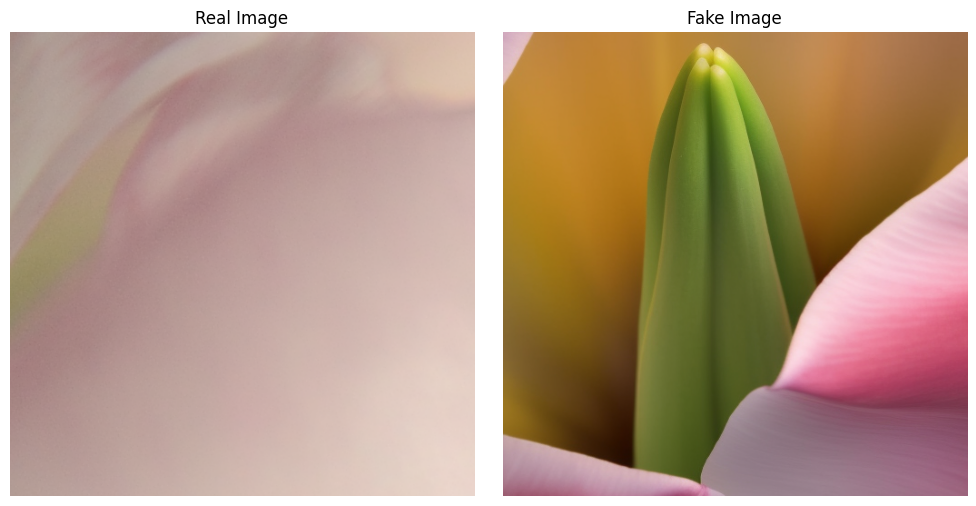

In [4]:
real_path="../data/real/r1b4e82c4t.png"
Fake_path="../data/fake/r1b4e82c4t.png"

real_image=load_image(real_path)
fake_image=load_image(Fake_path)

real_image=center_crop(real_image, 512)
fake_image=center_crop(fake_image, 512)
print("real_image properties:", real_image.shape, real_image.dtype, real_image.min(), real_image.max())
print("fake_image properties:", fake_image.shape, fake_image.dtype, fake_image.min(), fake_image.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(real_image)
axes[0].set_title("Real Image")
axes[0].axis("off")

axes[1].imshow(fake_image)
axes[1].set_title("Fake Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


*Both crops are 512×512. The fake image uses almost the full range (0–253), the real one is lower-contrast (93–237).*

## 2. Spectral analysis (FFT)
Pipeline: grayscale → subtract the mean → Hann window (removes the border cross) → 2D FFT → `fftshift` (zero frequency in the center).

### 2.1 Spectrum of one image pair

real_fft properties: (512, 512) complex128 (-268897.11624823674+0j) (190270.95597607244+339455.9074564312j)
fake_fft properties: (512, 512) complex128 (-976461.1257051043+256057.60915275227j) (767837.6658068625-567193.1086324183j)


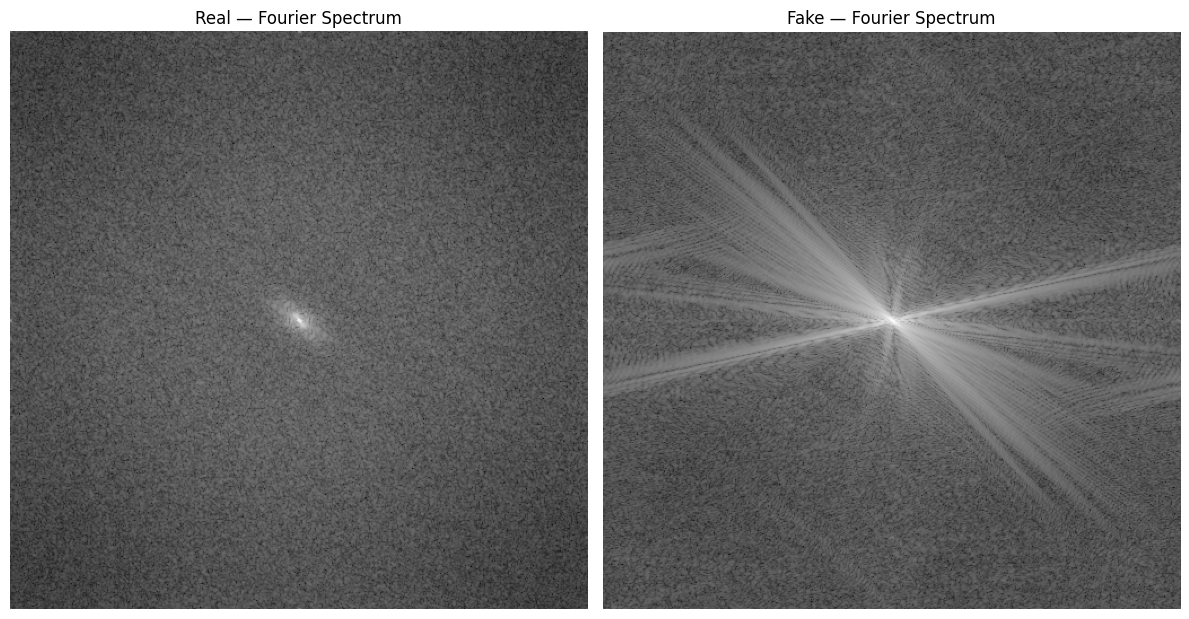

In [5]:
import numpy as np
from src.spectral import compute_fft , compute_power_spectrum
from pathlib import Path


real_fft = compute_fft(real_image)
fake_fft = compute_fft(fake_image)
print("real_fft properties:", real_fft.shape, real_fft.dtype, real_fft.min(), real_fft.max())
print("fake_fft properties:", fake_fft.shape, fake_fft.dtype, fake_fft.min(), fake_fft.max())

# Compute log-magnitude spectra
real_spectrum = np.log1p(np.abs(real_fft))
fake_spectrum = np.log1p(np.abs(fake_fft))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 12))

vmin = min(real_spectrum.min(), fake_spectrum.min())
vmax = max(real_spectrum.max(), fake_spectrum.max())

axes[0].imshow(real_spectrum, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Real — Fourier Spectrum")

axes[1].imshow(fake_spectrum, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Fake — Fourier Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

*The real spectrum is compact around the center (smooth image). The fake one spreads energy to the borders with radial streaks, which come from sharp edges.*

### 2.2 Spectra of random images
Log-magnitude spectra of random real and fake images, shown on the same intensity scale.

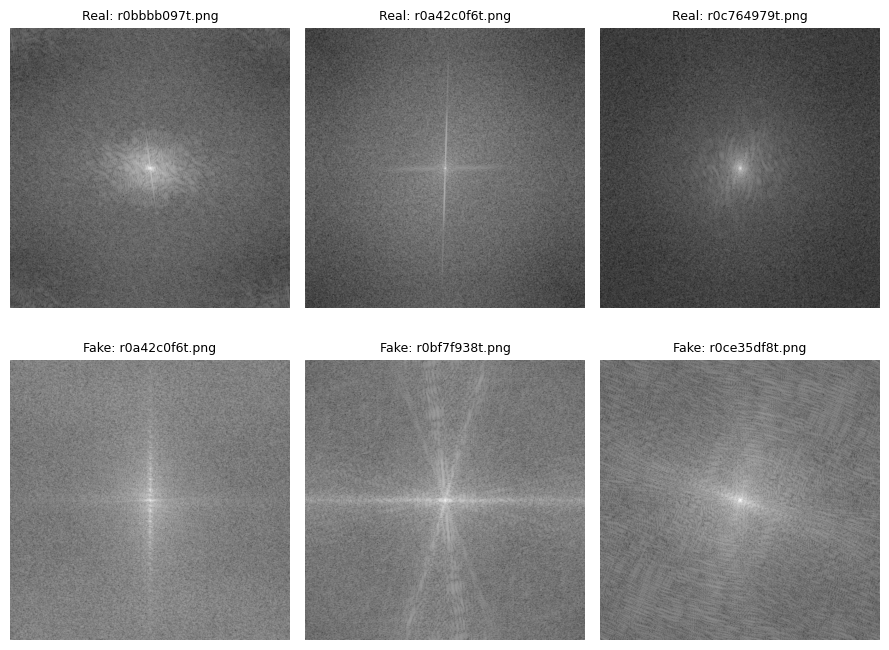

In [6]:

## COMPARING FFT OF FAKE AND REAL IMAGES

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from src.spectral import compute_fft , compute_power_spectrum

# Dataset location
root = Path.cwd().parent 
data_dir = root / "data"

rng = np.random.default_rng(seed=42)

def get_spectra(folder, n):
    all_paths = sorted(p for p in folder.iterdir())
    paths = rng.choice(all_paths, size=n, replace=False)

    spectra = []

    for path in paths:
        image = load_image(path)
        cropped = center_crop(image, 512)

        fft = compute_fft(cropped)
        spectrum = np.log1p(np.abs(fft))
        spectra.append(spectrum)

    return spectra, paths


n = 3  # Number of images per class
real_spectra, real_paths = get_spectra(data_dir / "real", n)
fake_spectra, fake_paths = get_spectra(data_dir / "fake", n)

# Same intensity scale for every spectrum
all_spectra = real_spectra + fake_spectra
vmin = min(s.min() for s in all_spectra)
vmax = max(s.max() for s in all_spectra)

fig, axes = plt.subplots(2, n, figsize=(3*n, 7), squeeze=False)

for row, (spectra, paths, label) in enumerate([
    (real_spectra, real_paths, "Real"),
    (fake_spectra, fake_paths, "Fake")
]):
    for j, (spectrum, path) in enumerate(zip(spectra, paths)):
        axes[row, j].imshow(
            spectrum, cmap="gray", vmin=vmin, vmax=vmax
        )
        axes[row, j].set_title(f"{label}: {path.name}", fontsize=9)
        axes[row, j].axis("off")

plt.tight_layout()
plt.show()


*Spectra vary a lot from one image to another (they depend on the content), so single spectra are not enough: we average over each class.*

### 2.3 Average power spectrum (raw power)
High-pass filtered, then averaged over all images of each class. The function is defined below, the next cell shows the result.

In [7]:
##Averaging the power spectra of all images in the dataset, with high pass filtering applied to each image before computing the power spectrum.


from src.spectral import compute_fft , compute_power_spectrum, high_pass_filter
def average_power_spectrum(folder, sigma=30):
    all_paths = sorted(p for p in folder.iterdir())

    total_power=np.zeros((512, 512), dtype=np.float64)
    for path in all_paths:
        image=load_image(path)
        image=center_crop(image, 512)

        fft=compute_fft(image)
        fft_filtered = high_pass_filter(fft, sigma=sigma)
        power = compute_power_spectrum(fft_filtered)
        total_power += power
    mean_power = total_power / len(all_paths)

    return mean_power




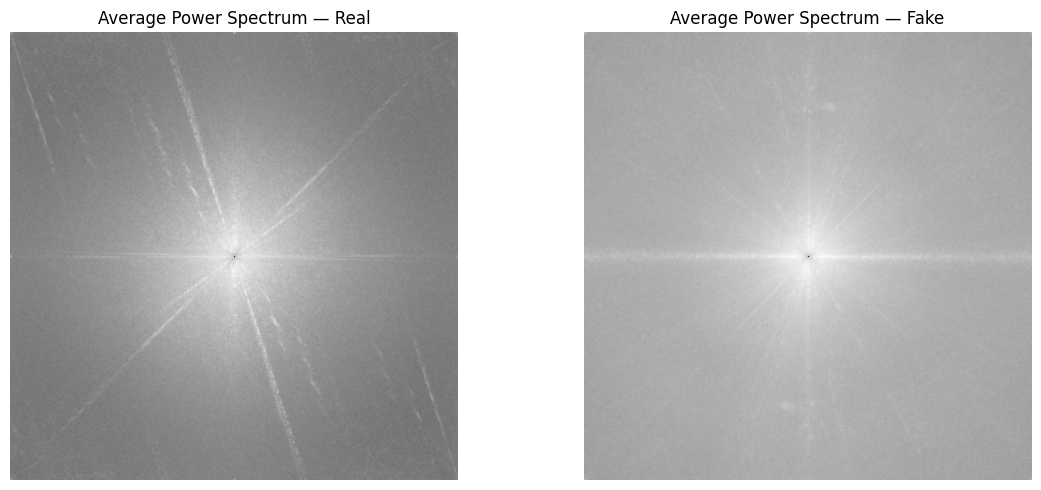

In [8]:
real_mean = average_power_spectrum(data_dir / "real", sigma=10)
fake_mean = average_power_spectrum(data_dir / "fake", sigma=10)

# Logarithmic scaling for visualization
real_log = np.log1p(real_mean)
fake_log = np.log1p(fake_mean)

# Common intensity range
vmin = min(real_log.min(), fake_log.min())
vmax = max(real_log.max(), fake_log.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(real_log, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Average Power Spectrum — Real")

axes[1].imshow(fake_log, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Average Power Spectrum — Fake")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

*Oblique streaks appear in the real average: a few high-contrast images dominate the mean of the raw power. The log-average in 2.4 avoids this.*

### 2.4 Mean log-spectrum and morphological dilation
Same high-pass filter, but `log10` is taken **before** averaging so every image weighs about the same. Dilation (`maximum_filter`, 5×5) makes isolated peaks easier to see.

In [9]:
from src.spectral import mean_log_spectrum
from scipy.ndimage import maximum_filter

def load_class(folder):
    return [center_crop(load_image(p), 512) for p in sorted(folder.glob("*.png"))]

real_spec = mean_log_spectrum(load_class(data_dir / "real"), sigma=10)
fake_spec = mean_log_spectrum(load_class(data_dir / "fake"), sigma=10)

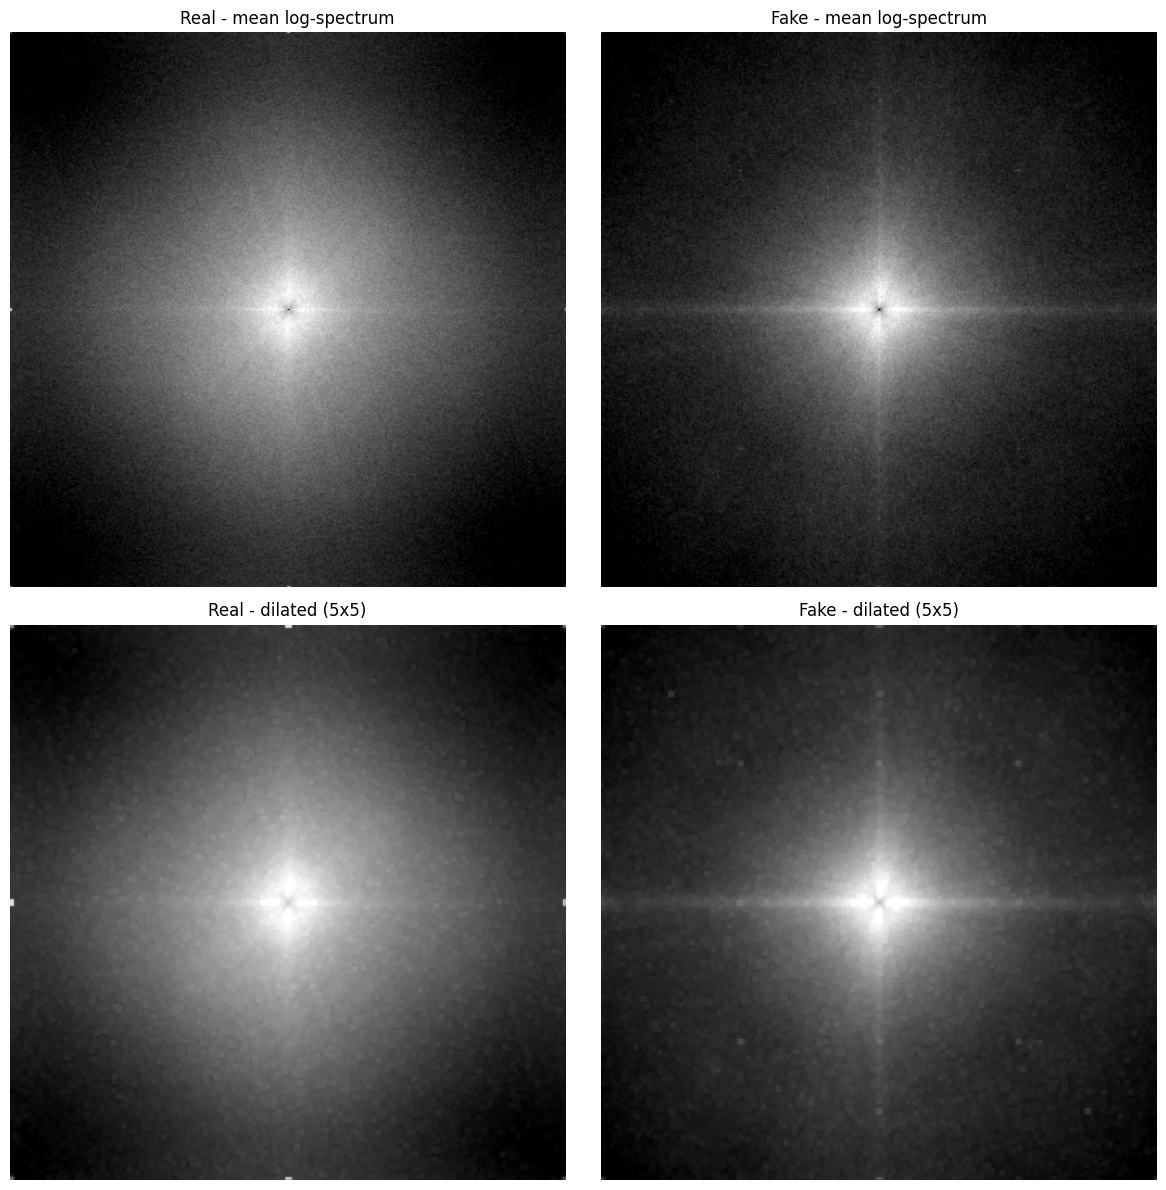

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for col, (spec, name) in enumerate([(real_spec, "Real"), (fake_spec, "Fake")]):
    dilated = maximum_filter(spec, size=5)               # dilation, 5x5 neighbourhood
    vmin, vmax = np.percentile(dilated, [1, 99.9])       # robust contrast
    axes[0, col].imshow(spec, cmap="gray", vmin=vmin, vmax=vmax)
    axes[0, col].set_title(f"{name} - mean log-spectrum")
    axes[1, col].imshow(dilated, cmap="gray", vmin=vmin, vmax=vmax)
    axes[1, col].set_title(f"{name} - dilated (5x5)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

*The streaks are gone. In the real dilated spectrum, small bright dots appear at the middle of each border (Nyquist frequencies, possible demosaicing trace). The fake one has a stronger axis cross and only faint scattered dots.*

## 3. Radial power profile
Each power spectrum is normalized by its total energy (removes the contrast/brightness effect), then averaged over rings of equal frequency radius `r` (r = 256 is Nyquist).

### 3.1 Profiles, differences and per-pair comparison

In [11]:
from src.spectral import radial_log_profile, radial_slope

def class_profiles(folder):
    paths = sorted(folder.glob("*.png"))
    profiles = np.stack([
        radial_log_profile(center_crop(load_image(p), 512)) for p in paths
    ])
    return paths, profiles

real_paths, real_prof = class_profiles(data_dir / "real")
fake_paths, fake_prof = class_profiles(data_dir / "fake")
print(real_prof.shape, fake_prof.shape)

(50, 256) (50, 256)


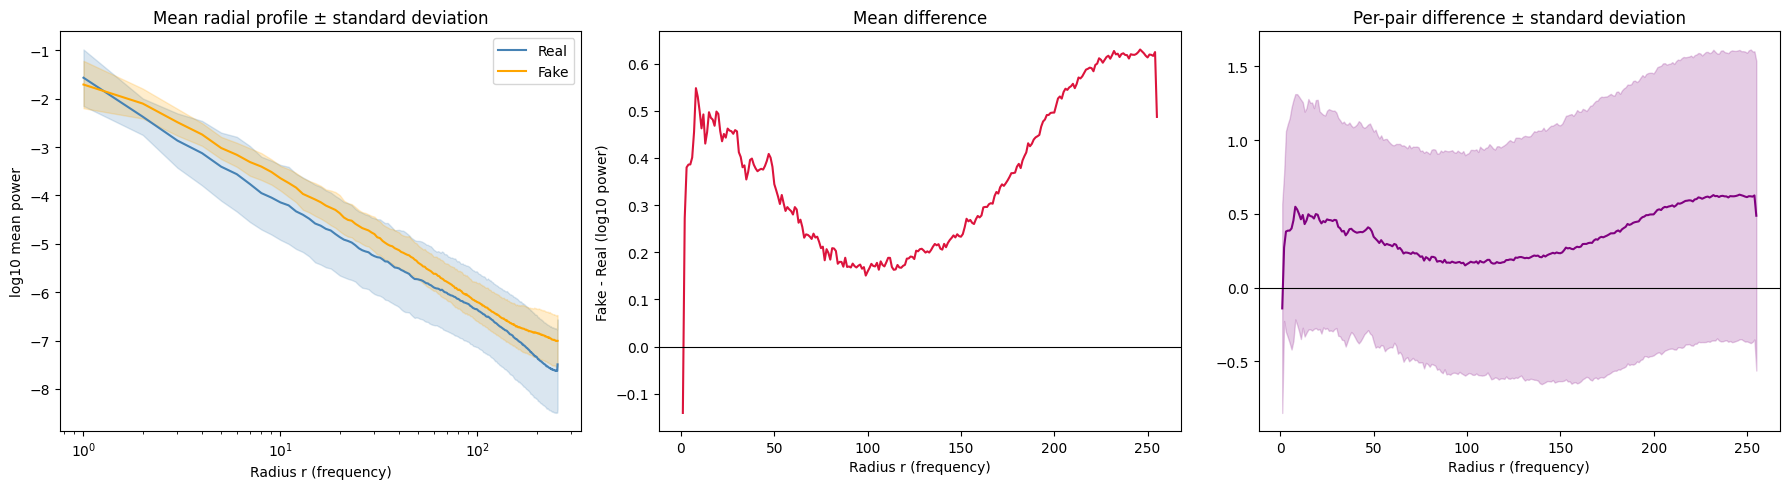

In [12]:
r = np.arange(real_prof.shape[1])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Mean profiles ± standard deviation (log scale on x)
for prof, label, color in [(real_prof, "Real", "steelblue"), (fake_prof, "Fake", "orange")]:
    m, s = prof.mean(axis=0), prof.std(axis=0)
    axes[0].plot(r[1:], m[1:], label=label, color=color)
    axes[0].fill_between(r[1:], (m - s)[1:], (m + s)[1:], color=color, alpha=0.2)
axes[0].set_xscale("log")
axes[0].set_xlabel("Radius r (frequency)")
axes[0].set_ylabel("log10 mean power")
axes[0].set_title("Mean radial profile ± standard deviation")
axes[0].legend()

# 2) Mean difference Fake - Real
diff = fake_prof.mean(axis=0) - real_prof.mean(axis=0)
axes[1].plot(r[1:], diff[1:], color="crimson")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("Radius r (frequency)")
axes[1].set_ylabel("Fake - Real (log10 power)")
axes[1].set_title("Mean difference")

# 3) Per-pair difference (same identifier), mean ± standard deviation
assert [p.name for p in real_paths] == [p.name for p in fake_paths]
pair_diff = fake_prof - real_prof
m, s = pair_diff.mean(axis=0), pair_diff.std(axis=0)
axes[2].plot(r[1:], m[1:], color="purple")
axes[2].fill_between(r[1:], (m - s)[1:], (m + s)[1:], color="purple", alpha=0.2)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xlabel("Radius r (frequency)")
axes[2].set_title("Per-pair difference ± standard deviation")

plt.tight_layout()
plt.show()

*After normalization the Fake − Real gap is small (+0.16 to +0.6 in log10) and U-shaped: largest at low and high frequencies. The bands overlap a lot, so this alone does not separate the classes.*

### 3.2 Radial slope
Slope of `log10 P` versus `log10 r`: how fast the energy decays with frequency.

Real slope: -2.509 ± 1.120
Fake slope: -2.455 ± 0.426


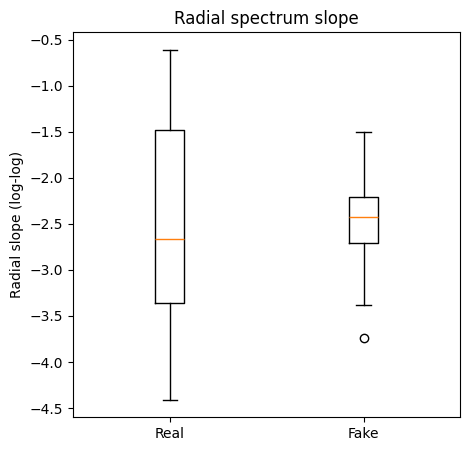

In [13]:
real_slopes = np.array([radial_slope(p)[0] for p in real_prof])
fake_slopes = np.array([radial_slope(p)[0] for p in fake_prof])

print(f"Real slope: {real_slopes.mean():.3f} ± {real_slopes.std():.3f}")
print(f"Fake slope: {fake_slopes.mean():.3f} ± {fake_slopes.std():.3f}")

plt.figure(figsize=(5, 5))
plt.boxplot([real_slopes, fake_slopes], tick_labels=["Real", "Fake"])
plt.ylabel("Radial slope (log-log)")
plt.title("Radial spectrum slope")
plt.show()

*Median slopes are close (real ≈ −2.65, fake ≈ −2.4). The difference is the spread: real images vary much more (−4.4 to −0.6) than fake ones.*

## 4. Spectral feature vector
`extract_spectral_features` turns each 512×512 image into **10 numbers**, computed on the energy-normalized power spectrum:
band energies (5), HF/LF ratio, radial slope, roughness and high-frequency bend of the radial profile, and energy at the Nyquist points of the axes.

The table is saved to `results/spectral_features.csv`.

In [14]:
import pandas as pd
from src.spectral import extract_spectral_features, SPECTRAL_FEATURE_NAMES

rows = []
for label in ("real", "fake"):
    for path in sorted((data_dir / label).glob("*.png")):
        features = extract_spectral_features(center_crop(load_image(path), 512))
        rows.append([path.name, label, *features])

df_spec = pd.DataFrame(rows, columns=["image_id", "label"] + SPECTRAL_FEATURE_NAMES)
(root / "results").mkdir(exist_ok=True)
df_spec.to_csv(root / "results" / "spectral_features.csv", index=False)

df_spec.groupby("label")[SPECTRAL_FEATURE_NAMES].mean().T.round(3)

label,fake,real
band_E_1_16,-0.145,-0.172
band_E_16_64,-0.898,-1.259
band_E_64_128,-1.518,-1.688
band_E_128_192,-1.875,-2.153
band_E_192_256,-1.963,-2.535
hf_lf_ratio,-1.556,-1.916
radial_slope,-2.455,-2.509
radial_fit_std,0.131,0.234
nyquist_dev,0.086,-0.126
nyquist_axis_peak,0.873,2.248


### 4.1 Which features separate the classes?
ROC-AUC of each feature alone (1.0 = perfect, 0.5 = useless). The sign does not matter, so the bars show max(AUC, 1 − AUC).

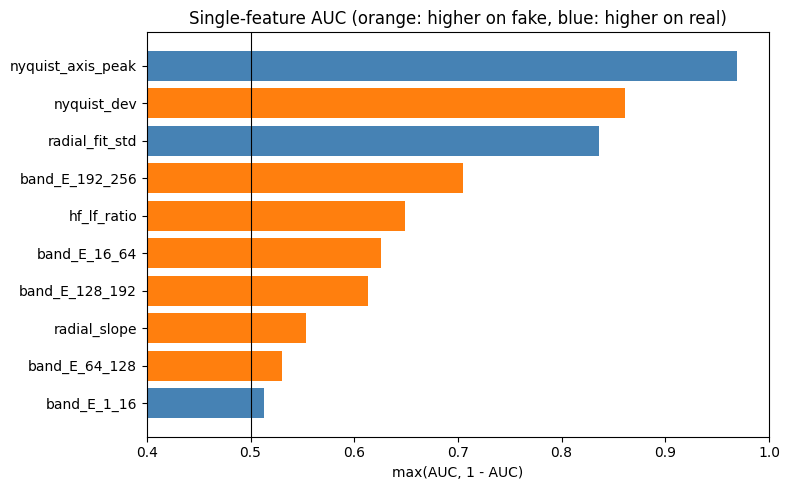

In [15]:
from sklearn.metrics import roc_auc_score

y = (df_spec["label"] == "fake").astype(int)
auc = {name: roc_auc_score(y, df_spec[name]) for name in SPECTRAL_FEATURE_NAMES}
auc_sorted = sorted(auc.items(), key=lambda kv: -abs(kv[1] - 0.5))

names = [n for n, _ in auc_sorted]
values = [max(a, 1 - a) for _, a in auc_sorted]
colors = ["tab:orange" if a > 0.5 else "steelblue" for _, a in auc_sorted]   # orange: higher on fake

plt.figure(figsize=(8, 5))
plt.barh(names[::-1], values[::-1], color=colors[::-1])
plt.axvline(0.5, color="k", lw=0.8)
plt.xlim(0.4, 1.0)
plt.xlabel("max(AUC, 1 - AUC)")
plt.title("Single-feature AUC (orange: higher on fake, blue: higher on real)")
plt.tight_layout()
plt.show()

*`nyquist_axis_peak` is by far the best feature (AUC ≈ 0.97, higher on real), then `nyquist_dev` and `radial_fit_std`.*

*Warning: a score this high may reflect how the images were prepared (resizing, resolution) rather than generation; it must be checked before being trusted.*